In [11]:
pip install catboost xgboost

In [12]:
import sys, sklearn, xgboost, catboost
print(sys.version.split()[0], sklearn.__version__, xgboost.__version__, catboost.__version__)
!cat /proc/cpuinfo | grep "model name" | head -1
!nproc
!free -h | head -2
!nvidia-smi -L

3.13.18 1.6.1 3.4.1 1.2.10
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       5.2Gi       4.8Gi       2.4Mi       3.0Gi       7.4Gi
/bin/bash: line 1: nvidia-smi: command not found


In [13]:
import pandas as pd
import numpy as np
from google.colab import drive

# Carga del dataset limpio

drive.mount('/content/drive')

path = '/content/drive/MyDrive/MachineLearningCVE/Data'

df_IDS = pd.read_csv(path + '/dataset_limpio.csv')
print(f"Dimensión: {df_IDS.shape}")
print(df_IDS['label'].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensión: (2522173, 45)
label
Benigno        2096342
DoS             193748
DDoS            128016
PortScan         90819
Brute Force       9152
Web Attack        2143
Bot               1953
Name: count, dtype: int64


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Se realiza la separacion de las features y la variable objetivo Label.
X = df_IDS.drop(columns=['label'])
y = df_IDS['label']

# Se cifra (encoding) label.
le = LabelEncoder()
y_enc = le.fit_transform(y)

print(f"Clases: {le.classes_}")
print(f"X shape: {X.shape}")
print(f"y shape: {y_enc.shape}")

Clases: ['Benigno' 'Bot' 'Brute Force' 'DDoS' 'DoS' 'PortScan' 'Web Attack']
X shape: (2522173, 44)
y shape: (2522173,)


In [15]:
# Se realiza la division de entrenamiento y evaluacion (train/test)
X_train, X_test, y_train, y_test = train_test_split(X, y_enc, test_size=0.2, random_state=42, stratify=y_enc)
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

np.save(path + '/Modelos/id_test.npy', X_test.index.values)

X_train shape: (2017738, 44)
X_test shape: (504435, 44)


In [16]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report
import time

modelos = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbosity=0, min_child_weight=0.01),
    'CatBoost': CatBoostClassifier(iterations=100, random_state=42, verbose=0)
}

resultados = {}

for nombre, modelo in modelos.items():
  inicio = time.time()
  modelo.fit(X_train, y_train)
  fin = time.time()

  y_pred = modelo.predict(X_test)
  accuracy = accuracy_score(y_test, y_pred)
  resultados[nombre] = {
      "modelo": modelo,
      "y_pred": y_pred,
      "accuracy": accuracy,
      "tiempo": round(fin - inicio, 2)
  }

  print(f"{nombre}: Accuracy = {accuracy:.4f}, tiempo = {resultados[nombre]['tiempo']} s")


Random Forest: Accuracy = 0.9986, tiempo = 933.88 s
XGBoost: Accuracy = 0.9991, tiempo = 327.7 s
CatBoost: Accuracy = 0.9990, tiempo = 362.98 s


In [17]:
# Reporte detallado por clase.
for nombre, res in resultados.items():
  print(f'Modelo: {nombre}')
  print(classification_report(y_test, res['y_pred'], target_names=le.classes_))
  print("-" * 53)

Modelo: Random Forest
              precision    recall  f1-score   support

     Benigno       1.00      1.00      1.00    419269
         Bot       0.91      0.79      0.84       390
 Brute Force       1.00      1.00      1.00      1830
        DDoS       1.00      1.00      1.00     25603
         DoS       1.00      1.00      1.00     38750
    PortScan       0.99      0.99      0.99     18164
  Web Attack       0.99      0.97      0.98       429

    accuracy                           1.00    504435
   macro avg       0.98      0.96      0.97    504435
weighted avg       1.00      1.00      1.00    504435

-----------------------------------------------------
Modelo: XGBoost
              precision    recall  f1-score   support

     Benigno       1.00      1.00      1.00    419269
         Bot       0.92      0.75      0.82       390
 Brute Force       1.00      1.00      1.00      1830
        DDoS       1.00      1.00      1.00     25603
         DoS       1.00      1.00      1

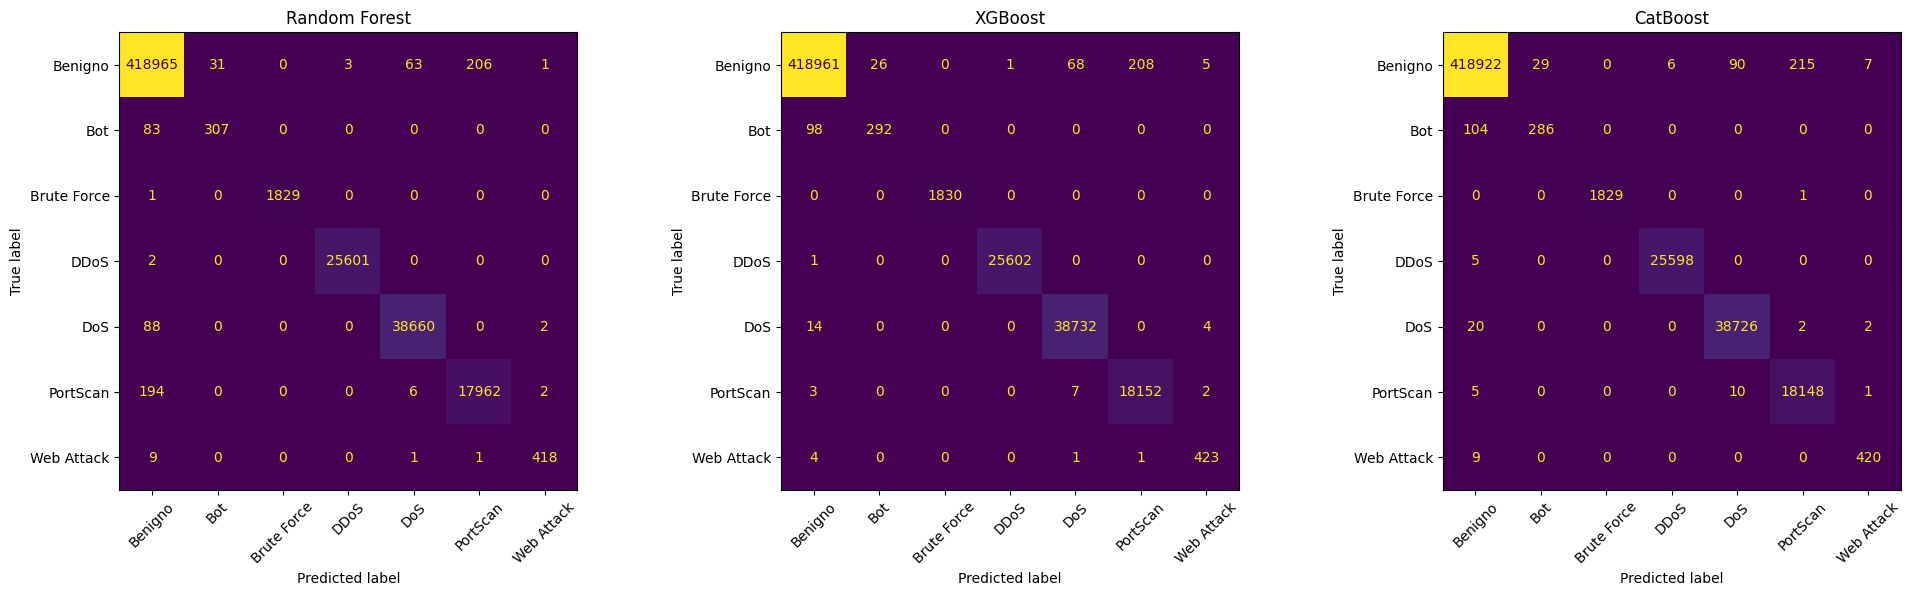

In [18]:
# Matrices de confusión
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (nombre, res) in zip(axes, resultados.items()):
  cm = confusion_matrix(y_test, res['y_pred'])
  disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
  disp.plot(ax=ax, colorbar=False, xticks_rotation=45)
  ax.set_title(nombre)

plt.tight_layout()
plt.show()

In [19]:
# Se guardan los modelos entrenados para hacer uso de estos mismos sin tener que reentrenarlos.

In [20]:
import joblib
import os
import json

ruta_modelos = path + '/Modelos'
os.makedirs(ruta_modelos, exist_ok=True)

for nombre, res in resultados.items():
  archivo = nombre.lower().replace(' ', '_')
  joblib.dump(res['modelo'], f'{ruta_modelos}/{archivo}.pkl')
  print(f"Guardado: {archivo}.pkl")

# Se guardó ademas el LabelEncoder
joblib.dump(le, f'{ruta_modelos}/label_encoder.pkl')
print('Guardado: label_encoder.pkl')

with open(ruta_modelos + '/tiempos.json', 'w') as f:
  json.dump({n.replace(' ', ''): r['tiempo'] for n, r in resultados.items()}, f)

Guardado: random_forest.pkl
Guardado: xgboost.pkl
Guardado: catboost.pkl
Guardado: label_encoder.pkl
